# Multi-Seed Genetic Algorithm Experiment

**Evolutionary Prompt Optimization for LLM-Based Sentiment Analysis**

Question: does the GA produce consistently good prompts across different random initializations?

- Notebook 05 (seed 42) is **not modified and not rerun**. Its saved results are loaded from disk.
- This notebook runs **two additional GA runs: seeds 7 and 123**.
- `DATA_SEED = 42` is fixed, so all runs use exactly the same 1,000 optimization examples.
  `GA_SEEDS` only controls the evolutionary randomness.
- Each run has its own output directory and its own fresh `PredictionCache()`, so execution-time
  and cost comparisons are fair.
- Validation is used only for descriptive evaluation after all runs. It never selects a prompt or seed.
- The final test set is never used.

Structure: A) setup, B) data and controls, C) load seed 42, D) run seeds 7 and 123,
E) analysis across seeds, F) descriptive validation, G) summary and ZIP.

## A1. Environment Setup
Same setup as notebook 05: clone or update the repository, install only missing packages.

In [1]:
import os
import sys
import json
import subprocess
import random
import time
import hashlib
import difflib
import zipfile
import importlib.util
from pathlib import Path
from datetime import datetime

REPO_URL = "https://github.com/sarrazer24/evolutionary-prompt-optimization.git"
REPO_DIR = Path("/kaggle/working/evolutionary-prompt-optimization")

if not REPO_DIR.exists():
    subprocess.run(
        ["git", "clone", "--branch", "main", "--single-branch", REPO_URL, str(REPO_DIR)],
        check=True,
    )
else:
    if not (REPO_DIR / ".git").exists():
        raise RuntimeError(f"{REPO_DIR} exists but is not a Git repository.")
    subprocess.run(["git", "-C", str(REPO_DIR), "fetch", "origin", "main"], check=True)
    subprocess.run(["git", "-C", str(REPO_DIR), "checkout", "main"], check=True)
    subprocess.run(["git", "-C", str(REPO_DIR), "pull", "--ff-only", "origin", "main"], check=True)

os.chdir(REPO_DIR)

REQUIRED_PACKAGES = {
    "transformers": "transformers",
    "accelerate": "accelerate",
    "datasets": "datasets",
    "sklearn": "scikit-learn",
    "numpy": "numpy",
    "pandas": "pandas",
    "matplotlib": "matplotlib",
    "scipy": "scipy",
}
missing_packages = [
    pkg for mod, pkg in REQUIRED_PACKAGES.items()
    if importlib.util.find_spec(mod) is None
]
if missing_packages:
    print("Installing missing packages:", missing_packages)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *missing_packages], check=True)
else:
    print("All required packages are already installed.")

if str(REPO_DIR) not in sys.path:
    sys.path.insert(0, str(REPO_DIR))

print("Project directory:", Path.cwd())
print("Setup completed.")

Cloning into '/kaggle/working/evolutionary-prompt-optimization'...


All required packages are already installed.
Project directory: /kaggle/working/evolutionary-prompt-optimization
Setup completed.


## A2. Imports, Seeds and GPU Check

Two separate seed concepts:
- `DATA_SEED`: fixed at 42. Used only by `stratified_sample`. It reproduces the exact seed-42 sample.
- `GA_SEEDS`: used only by `run_evolution`, which creates its own `random.Random(seed)` and calls
  `llm.set_seed(seed)` for the LLM's sampled generations (initial prompts, crossover, mutation).

Fitness evaluation is greedy decoding, so it is deterministic and independent of the GA seed.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display, FileLink

from src.data.sst2_data import load_saved_splits, stratified_sample
from src.llm.config import ModelConfig
from src.llm.model_interface import LLMInterface
from src.prompts.baseline_prompts import get_baseline_prompt_texts
from src.evaluation.evaluation import PredictionCache, evaluate_prompt
from src.genetic_algorithm.optimizer import run_evolution

DATA_SEED = 42            # dataset sampling only; never changes
SEED_ORIGINAL = 42        # original experiment (loaded, not rerun)
GA_SEEDS = [7, 123]       # additional independent GA runs
ALL_SEEDS = [SEED_ORIGINAL] + GA_SEEDS

if not torch.cuda.is_available():
    raise RuntimeError("No GPU detected. Enable GPU acceleration in Kaggle settings.")

GPU_NAME = torch.cuda.get_device_name(0)
CUDA_VERSION = torch.version.cuda

print("Data seed:", DATA_SEED)
print("GA seeds:", ALL_SEEDS, "(42 loaded from disk; new runs:", GA_SEEDS, ")")
print("GPU:", GPU_NAME, "| CUDA:", CUDA_VERSION, "| PyTorch:", torch.__version__)

Data seed: 42
GA seeds: [42, 7, 123] (42 loaded from disk; new runs: [7, 123] )
GPU: Tesla T4 | CUDA: 13.0 | PyTorch: 2.11.0+cu130


## B1. Load the Optimization Sample

Identical to notebook 05. A SHA-256 hash of the examples and labels is stored with every run,
so identical data across runs can be verified.

In [3]:
DATA_DIR = Path("data/processed")
for file_path in [DATA_DIR / "opt.csv", DATA_DIR / "val.csv", DATA_DIR / "split_info.json"]:
    if not file_path.exists():
        raise FileNotFoundError(f"Required dataset file not found: {file_path}")

splits = load_saved_splits(str(DATA_DIR))

N_OPT = 1000
opt_sample = stratified_sample(splits.opt, n=N_OPT, seed=DATA_SEED)

examples = opt_sample["text"].tolist()
labels = opt_sample["label"].tolist()

assert len(examples) == N_OPT == len(labels)
assert set(labels).issubset({0, 1})

DATA_HASH = hashlib.sha256(
    json.dumps([examples, labels], ensure_ascii=False).encode("utf-8")
).hexdigest()

print("Optimization examples:", len(examples))
print(opt_sample["label"].value_counts().sort_index().to_string())
print("Data hash:", DATA_HASH[:16], "...")

Optimization examples: 1000
label
0    442
1    558
Data hash: ab937736a4096f2d ...


## B2. Load the Model and the Manual Prompts

Same pinned model revision and inference configuration as notebook 05.

In [4]:
model_config = ModelConfig()
llm = LLMInterface(model_config)
llm.load_model()

seed_prompts = get_baseline_prompt_texts()
if not seed_prompts:
    raise ValueError("No baseline prompts were returned.")
manual_prompts = {f"Manual {i}": p for i, p in enumerate(seed_prompts, start=1)}

print("Model:", llm.model_id)
print("Revision:", model_config.revision)
print("Inference configuration:", llm.inference_config)
print("Manual prompts:", len(seed_prompts))

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Model: Qwen/Qwen2.5-1.5B-Instruct@989aa7980e4cf806f80c7fef2b1adb7bc71aa306
Revision: 989aa7980e4cf806f80c7fef2b1adb7bc71aa306
Inference configuration: {'decoding': 'greedy', 'max_new_tokens': 8, 'repetition_penalty': 1.0, 'dtype': 'float16', 'user_template': 'review-sentiment-v1'}
Manual prompts: 8


## B3. GA Configuration and Helpers

All hyperparameters are identical to notebook 05. Only the seed differs between runs.
`evaluate_on` and `metrics_row` are the same helpers used in notebook 05, so tables are consistent.

In [5]:
POPULATION_SIZE = 12
GENERATIONS = 10
ELITE_COUNT = 2
TOURNAMENT_SIZE = 3
CROSSOVER_RATE = 0.70
MUTATION_RATE = 0.30
EARLY_STOPPING_PATIENCE = None

HYPERPARAMETERS = {
    "population_size": POPULATION_SIZE,
    "generations": GENERATIONS,
    "elite_count": ELITE_COUNT,
    "tournament_size": TOURNAMENT_SIZE,
    "crossover_rate": CROSSOVER_RATE,
    "mutation_rate": MUTATION_RATE,
    "early_stopping_patience": EARLY_STOPPING_PATIENCE,
}

RUNS_ROOT = Path("/kaggle/working/outputs/genetic_algorithm")
SUMMARY_DIR = RUNS_ROOT / "multi_seed_summary"


def pick(d, *keys, default=None):
    for k in keys:
        if k in d:
            return d[k]
    if default is not None:
        return default
    raise KeyError(f"None of {keys} found. Available keys: {list(d.keys())}")


def evaluate_on(prompt, texts, gold, cache, split_name):
    return evaluate_prompt(
        prompt=prompt,
        examples=texts,
        labels=gold,
        predict_fn=llm.predict_raw_batch,
        model_id=llm.model_id,
        inference_config=llm.inference_config,
        cache=cache,
        batch_size=None,
        split_name=split_name,
    )


def metrics_row(name, prompt_type, res):
    m = res["metrics"]
    return {
        "prompt_name": name,
        "type": prompt_type,
        "macro_f1": pick(m, "f1_macro", "macro_f1"),
        "accuracy": m["accuracy"],
        "precision_macro": pick(m, "precision_macro", "macro_precision"),
        "recall_macro": pick(m, "recall_macro", "macro_recall"),
        "n_invalid": m["n_invalid"],
        "invalid_rate": m["invalid_rate"],
    }


print("Hyperparameters:", HYPERPARAMETERS)

Hyperparameters: {'population_size': 12, 'generations': 10, 'elite_count': 2, 'tournament_size': 3, 'crossover_rate': 0.7, 'mutation_rate': 0.3, 'early_stopping_patience': None}


## C. Load the Original Seed-42 Results (no rerun)

The seed-42 results are read from the files saved by notebook 05 (`history.json`,
`best_individual.json`, `experiment_config.json`). The notebook looks for them in the working
directory, then in `/kaggle/input` (a Kaggle Dataset containing the downloaded results, either the
extracted folder or `genetic_algorithm_experiment_01.zip`).

It then checks that the original run used the same hyperparameters and model revision as this notebook.
A later cell re-evaluates the seed-42 prompt on today's sample to confirm the data is identical.

In [6]:
def find_seed42_dir():
    direct = [RUNS_ROOT / "experiment_01", Path("/kaggle/working/experiment_01")]
    for c in direct:
        if (c / "history.json").exists() and (c / "best_individual.json").exists():
            return c

    for root in [Path("/kaggle/input"), Path("/kaggle/working")]:
        if not root.exists():
            continue
        for hp in root.rglob("history.json"):
            d = hp.parent
            cfg = d / "experiment_config.json"
            if (d / "best_individual.json").exists() and cfg.exists():
                try:
                    if json.load(open(cfg, encoding="utf-8")).get("random_seed") == 42:
                        return d
                except Exception:
                    continue
        for zp in root.rglob("genetic_algorithm_experiment_01.zip"):
            target = Path("/kaggle/working/seed42_restored")
            target.mkdir(parents=True, exist_ok=True)
            with zipfile.ZipFile(zp) as z:
                z.extractall(target)
            if (target / "history.json").exists():
                return target

    raise FileNotFoundError(
        "Seed-42 results not found. Upload the downloaded genetic_algorithm_experiment_01.zip "
        "(or its extracted folder) as a Kaggle Dataset and attach it to this notebook."
    )


def read_history(path):
    h = json.load(open(path, encoding="utf-8"))
    if isinstance(h, dict):
        h = h.get("history", h)
    return h


def load_run(run_dir, seed):
    run_dir = Path(run_dir)
    history = read_history(run_dir / "history.json")
    best = json.load(open(run_dir / "best_individual.json", encoding="utf-8"))
    if (run_dir / "run_meta.json").exists():
        meta = json.load(open(run_dir / "run_meta.json", encoding="utf-8"))
    else:
        meta = json.load(open(run_dir / "experiment_config.json", encoding="utf-8"))
        meta["execution_time_seconds"] = meta.get("execution_time_seconds")
    return {"seed": seed, "dir": run_dir, "history": pd.DataFrame(history), "best": best, "meta": meta}


seed42_dir = find_seed42_dir()
print("Seed-42 results found in:", seed42_dir)

cfg42 = json.load(open(seed42_dir / "experiment_config.json", encoding="utf-8"))

mismatches = []
for key, expected in [
    ("population_size", POPULATION_SIZE),
    ("elite_count", ELITE_COUNT),
    ("tournament_size", TOURNAMENT_SIZE),
    ("crossover_rate", CROSSOVER_RATE),
    ("mutation_rate", MUTATION_RATE),
    ("optimization_sample_size", N_OPT),
    ("random_seed", 42),
]:
    if cfg42.get(key) != expected:
        mismatches.append((key, cfg42.get(key), expected))
if cfg42.get("generations_requested") != GENERATIONS:
    mismatches.append(("generations_requested", cfg42.get("generations_requested"), GENERATIONS))
if cfg42.get("model_revision") != model_config.revision:
    mismatches.append(("model_revision", cfg42.get("model_revision"), model_config.revision))

if mismatches:
    raise ValueError(f"Seed-42 configuration differs from this notebook: {mismatches}")

print("Controls verified: hyperparameters, sample size and model revision match the original run.")

Seed-42 results found in: /kaggle/input/notebooks/hibazoubir/05-genetic-algorithm-experiment/outputs/genetic_algorithm/experiment_01
Controls verified: hyperparameters, sample size and model revision match the original run.


## D1. Function for One GA Run

`run_one_seed(seed)`:
- refuses to write into a non-empty directory (original results cannot be overwritten);
- creates a fresh `PredictionCache()` for this run only;
- calls the existing `run_evolution` with identical examples, labels and hyperparameters;
- saves `history.csv/json`, `best_prompt.txt`, `best_individual.json` (done by `run_evolution`);
- saves `run_meta.json` with the seed, data hash, duration, cache size, and environment.

No module is modified. `run_evolution` reseeds Python's RNG and torch internally.

In [7]:
def run_one_seed(ga_seed):
    out_dir = RUNS_ROOT / f"experiment_seed_{ga_seed}"
    if out_dir.exists() and any(out_dir.iterdir()):
        raise FileExistsError(f"{out_dir} is not empty. Results are never overwritten.")
    out_dir.mkdir(parents=True, exist_ok=True)

    cache = PredictionCache()          # fresh cache: fair cost comparison
    print(f"Starting GA run with seed {ga_seed} ...")
    start = time.perf_counter()

    res = run_evolution(
        llm=llm,
        examples=examples,
        labels=labels,
        population_size=POPULATION_SIZE,
        generations=GENERATIONS,
        elite_count=ELITE_COUNT,
        tournament_size=TOURNAMENT_SIZE,
        crossover_rate=CROSSOVER_RATE,
        mutation_rate=MUTATION_RATE,
        seed_prompts=seed_prompts,
        seed=ga_seed,
        cache=cache,
        batch_size=None,
        early_stopping_patience=EARLY_STOPPING_PATIENCE,
        output_dir=str(out_dir),
    )

    duration = time.perf_counter() - start

    meta = {
        "ga_seed": ga_seed,
        "data_seed": DATA_SEED,
        "data_hash": DATA_HASH,
        "n_optimization_examples": N_OPT,
        "model_id": llm.model_id,
        "model_revision": model_config.revision,
        "inference_config": llm.inference_config,
        "hyperparameters": HYPERPARAMETERS,
        "fresh_cache": True,
        "cache_entries_after_run": len(cache),
        "execution_time_seconds": round(duration, 2),
        "gpu_name": GPU_NAME,
        "cuda_version": CUDA_VERSION,
        "pytorch_version": torch.__version__,
        "created_at": datetime.now().isoformat(),
    }
    with open(out_dir / "run_meta.json", "w", encoding="utf-8") as f:
        json.dump(meta, f, indent=4, default=str)

    best = res["best_individual"]
    print(f"\nSeed {ga_seed} finished in {duration:.1f} s")
    print(f"Best Macro F1: {best.fitness:.6f} (generation {best.generation})")
    print("Best prompt:", best.prompt)
    return out_dir

## D2. Run Seed 7
About 13 minutes. Run this cell, wait for it to finish, then run D3.

In [8]:
dir_seed_7 = run_one_seed(7)

Starting GA run with seed 7 ...
Generation 0: Best=0.9366, Average=0.9141, Worst=0.8794, Diversity=1.00
Generation 1: Best=0.9366, Average=0.9179, Worst=0.8704, Diversity=1.00


crossover_prompts: no valid child after 3 attempts; returning parent1


Generation 2: Best=0.9366, Average=0.9272, Worst=0.9059, Diversity=0.92


crossover_prompts: no valid child after 3 attempts; returning parent1


Generation 3: Best=0.9415, Average=0.9238, Worst=0.8854, Diversity=0.83


crossover_prompts: no valid child after 3 attempts; returning parent1
crossover_prompts: no valid child after 3 attempts; returning parent1
crossover_prompts: no valid child after 3 attempts; returning parent1
crossover_prompts: no valid child after 3 attempts; returning parent1


... (3 outputs left out)

crossover_prompts: no valid child after 3 attempts; returning parent1
mutate_prompt: no valid mutation after 3 attempts; returning parent


Generation 6: Best=0.9415, Average=0.9348, Worst=0.8999, Diversity=0.42


mutate_prompt: no valid mutation after 3 attempts; returning parent
mutate_prompt: no valid mutation after 3 attempts; returning parent


Generation 7: Best=0.9415, Average=0.9292, Worst=0.8850, Diversity=0.33
Generation 8: Best=0.9415, Average=0.9342, Worst=0.9098, Diversity=0.42
Generation 9: Best=0.9415, Average=0.9314, Worst=0.8944, Diversity=0.33

Seed 7 finished in 932.4 s
Best Macro F1: 0.941547 (generation 3)
Best prompt: Classify the sentiment as positive or negative: positive or negative. Answer with exactly one word: positive or negative.


## D3. Run Seed 123
About 13 minutes. If the kernel restarts after seed 7, rerun sections A-C and B-cells only,
skip D2 (seed 7 is on disk) and run this cell.

In [9]:
dir_seed_123 = run_one_seed(123)

Starting GA run with seed 123 ...
Generation 0: Best=0.9364, Average=0.9159, Worst=0.8794, Diversity=1.00
Generation 1: Best=0.9373, Average=0.9278, Worst=0.8909, Diversity=0.75


mutate_prompt: no valid mutation after 3 attempts; returning parent


Generation 2: Best=0.9375, Average=0.9107, Worst=0.6723, Diversity=0.92
Generation 3: Best=0.9375, Average=0.9309, Worst=0.9178, Diversity=0.92
Generation 4: Best=0.9415, Average=0.9349, Worst=0.9276, Diversity=0.75
Generation 5: Best=0.9415, Average=0.9313, Worst=0.8949, Diversity=0.67
Generation 6: Best=0.9415, Average=0.9309, Worst=0.9107, Diversity=0.75
Generation 7: Best=0.9415, Average=0.9367, Worst=0.9192, Diversity=0.50
Generation 8: Best=0.9415, Average=0.9372, Worst=0.9177, Diversity=0.42
Generation 9: Best=0.9415, Average=0.9352, Worst=0.8953, Diversity=0.50

Seed 123 finished in 959.1 s
Best Macro F1: 0.941547 (generation 6)
Best prompt: Read the text. Classify sentiment as positive or negative. Answer with one word: positive or negative.


## E1. Load All Three Runs From Disk

All three runs are loaded the same way (from saved files), so the analysis treats them identically.

In [10]:
runs = {
    42: load_run(seed42_dir, 42),
    7: load_run(RUNS_ROOT / "experiment_seed_7", 7),
    123: load_run(RUNS_ROOT / "experiment_seed_123", 123),
}

for s, r in runs.items():
    print(f"Seed {s}: {len(r['history'])} generations loaded from {r['dir']}")

# Control: the same examples were used in the new runs.
for s in GA_SEEDS:
    assert runs[s]["meta"]["data_hash"] == DATA_HASH, f"Data hash mismatch for seed {s}"
print("Data hash identical for all new runs.")

Seed 42: 10 generations loaded from /kaggle/input/notebooks/hibazoubir/05-genetic-algorithm-experiment/outputs/genetic_algorithm/experiment_01
Seed 7: 10 generations loaded from /kaggle/working/outputs/genetic_algorithm/experiment_seed_7
Seed 123: 10 generations loaded from /kaggle/working/outputs/genetic_algorithm/experiment_seed_123
Data hash identical for all new runs.


## E2. Manual Baseline and Consistency Check (separate cache)

The 8 manual prompts are evaluated on the same 1,000 examples using a **separate analysis cache**
(not a run cache, so run costs are unaffected). The three evolved prompts are re-evaluated too.
Their Macro F1 must equal the fitness stored by the GA. For seed 42 this confirms that this
notebook's sample is identical to the original experiment's sample.

In [11]:
analysis_cache = PredictionCache()

manual_rows = []
for name, prompt in manual_prompts.items():
    res = evaluate_on(prompt, examples, labels, analysis_cache, "opt")
    manual_rows.append(metrics_row(name, "Manual", res))

manual_df = pd.DataFrame(manual_rows).sort_values("macro_f1", ascending=False).reset_index(drop=True)
display(manual_df)

best_manual_name = manual_df.loc[0, "prompt_name"]
best_manual_prompt = manual_prompts[best_manual_name]
best_manual_f1 = float(manual_df.loc[0, "macro_f1"])
best_manual_acc = float(manual_df.loc[0, "accuracy"])
print(f"\nBest manual prompt: {best_manual_name} | Macro F1 = {best_manual_f1:.6f}")

print("\nConsistency check (stored GA fitness vs re-evaluation):")
for s, r in runs.items():
    res = evaluate_on(r["best"]["prompt"], examples, labels, analysis_cache, "opt")
    recomputed = float(pick(res["metrics"], "f1_macro", "macro_f1"))
    stored = float(r["best"]["fitness"])
    ok = abs(recomputed - stored) < 1e-6
    print(f"  seed {s}: stored {stored:.6f} | re-evaluated {recomputed:.6f} | {'OK' if ok else 'MISMATCH'}")
    assert ok, f"Seed {s}: re-evaluated fitness differs from stored fitness."

,prompt_name,type,macro_f1,accuracy,precision_macro,recall_macro,n_invalid,invalid_rate
0,Manual 3,Manual,0.936426,0.937,0.935091,0.938610,0,0.000
1,Manual 7,Manual,0.921056,0.918,0.923812,0.923231,7,0.007
2,Manual 8,Manual,0.920622,0.921,0.919927,0.925449,0,0.000
3,Manual 1,Manual,0.918697,0.919,0.918667,0.924362,0,0.000
4,Manual 6,Manual,0.916579,0.917,0.915773,0.921159,0,0.000
5,Manual 5,Manual,0.909792,0.910,0.911325,0.916768,0,0.000
6,Manual 2,Manual,0.893451,0.889,0.903544,0.898421,10,0.010
7,Manual 4,Manual,0.879439,0.879,0.890240,0.890401,1,0.001



Best manual prompt: Manual 3 | Macro F1 = 0.936426

Consistency check (stored GA fitness vs re-evaluation):
  seed 42: stored 0.943434 | re-evaluated 0.943434 | OK
  seed 7: stored 0.941547 | re-evaluated 0.941547 | OK
  seed 123: stored 0.941547 | re-evaluated 0.941547 | OK


## E3. Comparison Table Across the Three Runs

Two separate quantities per seed:
- **Initial advantage** = best generation-0 fitness minus best manual fitness
  (contribution of the initial population, which includes LLM-generated prompts).
- **Evolution gain** = final best fitness minus best generation-0 fitness
  (improvement observed after generation 0).

This is a comparison, not a causal attribution. Generation 0 contains the 8 manual prompts plus
4 LLM-generated prompts, and all runs share the same 8 manual prompts.

In [12]:
def normalize(p):
    return " ".join(str(p).split())

manual_norm = {normalize(p) for p in seed_prompts}

rows = []
for s, r in runs.items():
    h = r["history"]
    best = r["best"]
    gen0 = h.iloc[0]
    gen0_prompt = gen0["best_prompt"] if "best_prompt" in h.columns else None
    gen0_source = (
        "manual" if gen0_prompt is not None and normalize(gen0_prompt) in manual_norm
        else "generated"
    )
    best_f1 = float(best["fitness"])
    meta = r["meta"]
    rows.append({
        "ga_seed": s,
        "best_prompt": best["prompt"],
        "best_generation": best.get("generation"),
        "best_macro_f1_opt": best_f1,
        "best_accuracy_opt": float(best["accuracy"]),
        "best_prompt_invalid": (best.get("metadata") or {}).get("n_invalid"),
        "gen0_best_f1": float(gen0["best_fitness"]),
        "gen0_best_source": gen0_source,
        "initial_advantage_vs_manual": float(gen0["best_fitness"]) - best_manual_f1,
        "evolution_gain_after_gen0": best_f1 - float(gen0["best_fitness"]),
        "total_gain_vs_manual": best_f1 - best_manual_f1,
        "final_diversity": float(h["diversity"].iloc[-1]),
        "mean_diversity": float(h["diversity"].mean()),
        "cumulative_invalid": int(h["total_invalid"].sum()),
        "uncached_texts_evaluated": int(h["total_model_texts"].sum()),
        "execution_time_s": meta.get("execution_time_seconds"),
        "generations_evaluated": len(h),
    })

summary_df = pd.DataFrame(rows)
SUMMARY_DIR.mkdir(parents=True, exist_ok=True)
summary_df.to_csv(SUMMARY_DIR / "multi_seed_comparison.csv", index=False)

display(summary_df.drop(columns=["best_prompt"]))

# Statistics of best optimization Macro F1 across seeds.
f1s = summary_df["best_macro_f1_opt"].to_numpy()
stats = {
    "n_runs": int(len(f1s)),
    "mean": float(np.mean(f1s)),
    "std_sample": float(np.std(f1s, ddof=1)),
    "min": float(np.min(f1s)),
    "max": float(np.max(f1s)),
    "range": float(np.max(f1s) - np.min(f1s)),
}
print("\nBest optimization Macro F1 across seeds")
print(f"  mean  = {stats['mean']:.6f}")
print(f"  std   = {stats['std_sample']:.6f}  (sample std, n = {stats['n_runs']}; only a rough indicator)")
print(f"  range = {stats['min']:.6f} to {stats['max']:.6f}  (spread {stats['range'] * 100:.2f} points)")
print(f"  best manual baseline = {best_manual_f1:.6f}")

,ga_seed,best_generation,best_macro_f1_opt,best_accuracy_opt,best_prompt_invalid,gen0_best_f1,gen0_best_source,initial_advantage_vs_manual,evolution_gain_after_gen0,total_gain_vs_manual,final_diversity,mean_diversity,cumulative_invalid,uncached_texts_evaluated,execution_time_s,generations_evaluated
0,42,3,0.943434,0.944,0,0.940591,generated,0.004164,0.002844,0.007008,0.333333,0.566667,69,48951,778.41,10
1,7,3,0.941547,0.942,0,0.936563,generated,0.000137,0.004984,0.005121,0.333333,0.650000,43,55944,932.42,10
2,123,6,0.941547,0.942,0,0.936426,manual,0.000000,0.005121,0.005121,0.500000,0.716667,46,58941,959.11,10



Best optimization Macro F1 across seeds
  mean  = 0.942176
  std   = 0.001089  (sample std, n = 3; only a rough indicator)
  range = 0.941547 to 0.943434  (spread 0.19 points)
  best manual baseline = 0.936426


## E4. Fitness Evolution and Diversity Plots

Each seed is one colour, shared across the plots. Solid lines are best fitness, dashed lines are
average fitness. The horizontal line is the best manual prompt on the same sample.

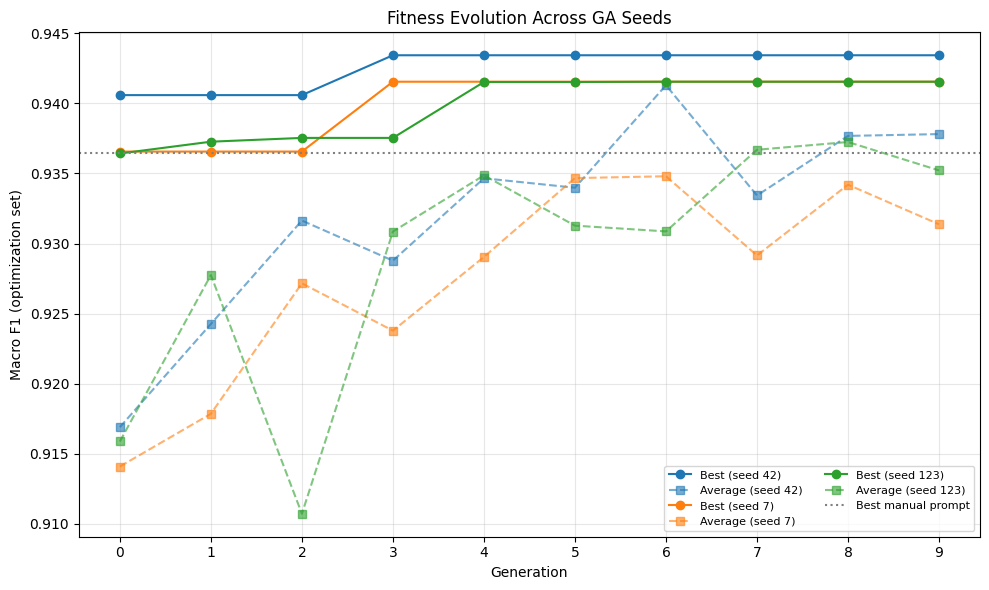

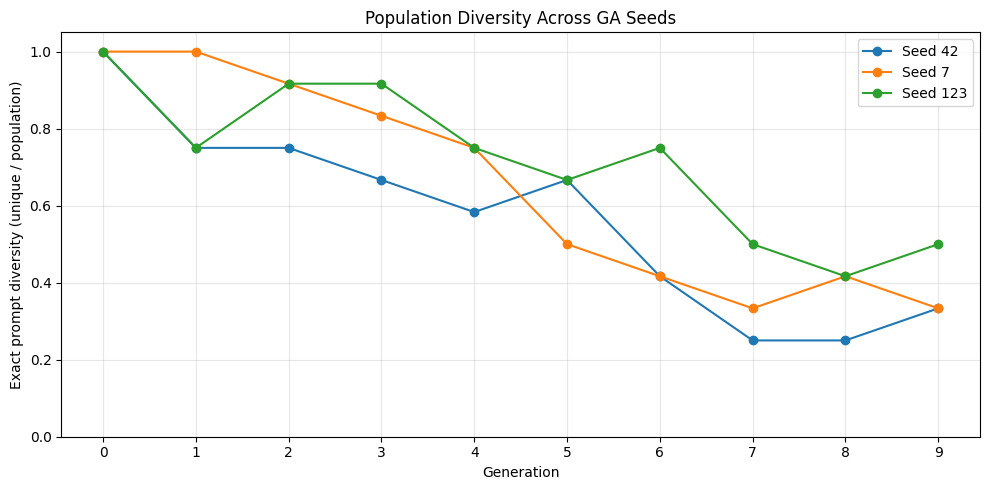

In [13]:
colors = {42: "tab:blue", 7: "tab:orange", 123: "tab:green"}

fig, ax = plt.subplots(figsize=(10, 6))
for s, r in runs.items():
    h = r["history"]
    ax.plot(h["generation"], h["best_fitness"], marker="o", color=colors[s], label=f"Best (seed {s})")
    ax.plot(h["generation"], h["average_fitness"], marker="s", linestyle="--", alpha=0.6,
            color=colors[s], label=f"Average (seed {s})")
ax.axhline(best_manual_f1, color="gray", linestyle=":", label="Best manual prompt")
ax.set_xlabel("Generation")
ax.set_ylabel("Macro F1 (optimization set)")
ax.set_title("Fitness Evolution Across GA Seeds")
ax.set_xticks(range(GENERATIONS))
ax.grid(True, alpha=0.3)
ax.legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.savefig(SUMMARY_DIR / "fitness_evolution_all_seeds.png", dpi=300)
plt.show()

fig, ax = plt.subplots(figsize=(10, 5))
for s, r in runs.items():
    h = r["history"]
    ax.plot(h["generation"], h["diversity"], marker="o", color=colors[s], label=f"Seed {s}")
ax.set_xlabel("Generation")
ax.set_ylabel("Exact prompt diversity (unique / population)")
ax.set_title("Population Diversity Across GA Seeds")
ax.set_xticks(range(GENERATIONS))
ax.set_ylim(0, 1.05)
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.savefig(SUMMARY_DIR / "diversity_all_seeds.png", dpi=300)
plt.show()

## E5. Execution Time and Computational Cost

Every run used a fresh cache, so these numbers are comparable.
`uncached texts` is the number of prompt-example pairs sent to the model (cache misses), not
the number of GPU calls. Time also includes LLM calls for generating prompts, crossover and mutation,
and can vary a little with GPU state.

,ga_seed,execution_time_s,uncached_texts_evaluated,generations_evaluated,seconds_per_generation,ms_per_uncached_text
0,42,778.41,48951,10,77.841,15.901820
1,7,932.42,55944,10,93.242,16.667024
2,123,959.11,58941,10,95.911,16.272374


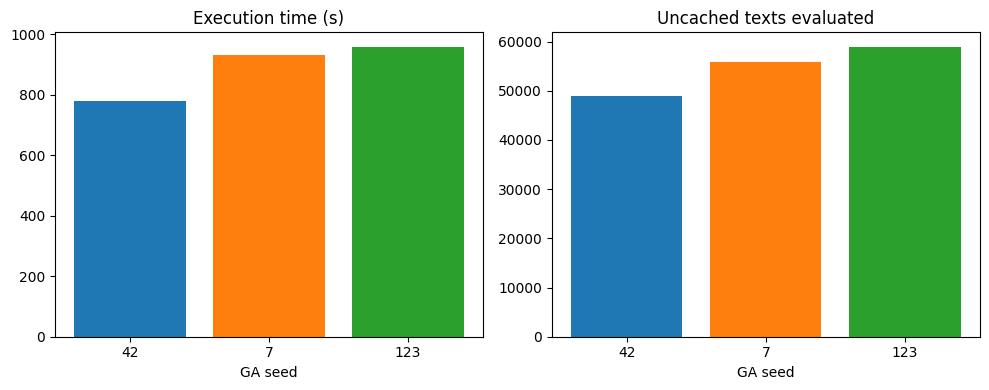

In [14]:
cost_df = summary_df[["ga_seed", "execution_time_s", "uncached_texts_evaluated", "generations_evaluated"]].copy()
cost_df["seconds_per_generation"] = cost_df["execution_time_s"] / cost_df["generations_evaluated"]
cost_df["ms_per_uncached_text"] = 1000 * cost_df["execution_time_s"] / cost_df["uncached_texts_evaluated"]
display(cost_df)
cost_df.to_csv(SUMMARY_DIR / "computational_cost.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
x = [str(s) for s in cost_df["ga_seed"]]
axes[0].bar(x, cost_df["execution_time_s"], color=[colors[s] for s in cost_df["ga_seed"]])
axes[0].set_title("Execution time (s)")
axes[0].set_xlabel("GA seed")
axes[1].bar(x, cost_df["uncached_texts_evaluated"], color=[colors[s] for s in cost_df["ga_seed"]])
axes[1].set_title("Uncached texts evaluated")
axes[1].set_xlabel("GA seed")
plt.tight_layout()
plt.savefig(SUMMARY_DIR / "computational_cost.png", dpi=300)
plt.show()

## E6. Qualitative Comparison of the Evolved Prompts

The three best prompts are printed together, followed by two similarity measures:
character-level similarity (difflib ratio) and word-set overlap (Jaccard). 1.0 means identical.
These measure surface similarity only, not meaning.

In [15]:
print("BEST EVOLVED PROMPTS")
print("=" * 70)
for s, r in runs.items():
    b = r["best"]
    print(f"\nSeed {s} | generation {b.get('generation')} | Macro F1 {float(b['fitness']):.6f}")
    print(b["prompt"])

prompts_by_seed = {s: normalize(r["best"]["prompt"]) for s, r in runs.items()}

def char_sim(a, b):
    return difflib.SequenceMatcher(None, a.lower(), b.lower()).ratio()

def jaccard(a, b):
    A, B = set(a.lower().split()), set(b.lower().split())
    return len(A & B) / len(A | B) if A | B else 1.0

seeds_sorted = list(prompts_by_seed)
char_matrix = pd.DataFrame(
    [[char_sim(prompts_by_seed[a], prompts_by_seed[b]) for b in seeds_sorted] for a in seeds_sorted],
    index=seeds_sorted, columns=seeds_sorted,
).round(3)
jacc_matrix = pd.DataFrame(
    [[jaccard(prompts_by_seed[a], prompts_by_seed[b]) for b in seeds_sorted] for a in seeds_sorted],
    index=seeds_sorted, columns=seeds_sorted,
).round(3)

print("\nCharacter-level similarity:")
display(char_matrix)
print("Word-set overlap (Jaccard):")
display(jacc_matrix)

print("Identical prompt strings across seeds:", len(set(prompts_by_seed.values())) < len(prompts_by_seed))
print("Best prompt identical to a manual prompt:",
      {s: p in manual_norm for s, p in prompts_by_seed.items()})

print("\nGeneration-0 best prompts:")
for s, r in runs.items():
    h = r["history"]
    if "best_prompt" in h.columns:
        print(f"  seed {s}: {h['best_prompt'].iloc[0]}")

BEST EVOLVED PROMPTS

Seed 42 | generation 3 | Macro F1 0.943434
Is the text positive or negative? Answer with exactly one word: positive or negative.

Seed 7 | generation 3 | Macro F1 0.941547
Classify the sentiment as positive or negative: positive or negative. Answer with exactly one word: positive or negative.

Seed 123 | generation 6 | Macro F1 0.941547
Read the text. Classify sentiment as positive or negative. Answer with one word: positive or negative.

Character-level similarity:


,42,7,123
42,1.000,0.796,0.791
7,0.786,1.000,0.780
123,0.791,0.780,1.000


Word-set overlap (Jaccard):


,42,7,123
42,1.000,0.562,0.471
7,0.562,1.000,0.733
123,0.471,0.733,1.000


Identical prompt strings across seeds: False
Best prompt identical to a manual prompt: {42: False, 7: False, 123: False}

Generation-0 best prompts:
  seed 42: Decide if the text is positive or negative. Answer with exactly one word: positive or negative.
  seed 7: Classify the sentiment of the following text as positive or negative. Answer with exactly one word: positive or negative.
  seed 123: Look for praise, enthusiasm and approval (positive) versus complaints, disappointment and criticism (negative). Weigh the overall tone of the text, then output exactly one word: positive or negative.


## F. Descriptive Validation (no selection)

The best manual prompt (chosen on the **optimization** set) and the three evolved prompts are evaluated
on the validation split with a separate cache. This is **descriptive only**:
- no prompt or seed is chosen using these numbers;
- validation never feeds back into the GA;
- the table is not sorted by validation score, and no winner is declared.

The final test set is not touched.

Validation examples: 13468
Evaluating best manual prompt (Manual 3) ...
Evaluating evolved prompt, seed 42 ...
Evaluating evolved prompt, seed 7 ...
Evaluating evolved prompt, seed 123 ...


,prompt_name,type,macro_f1,accuracy,precision_macro,recall_macro,n_invalid,invalid_rate
0,Best manual (Manual 3),Manual,0.926151,0.926864,0.924964,0.927918,0,0.000000
1,Evolved (seed 42),Evolved,0.933148,0.933398,0.932713,0.933809,13,0.000965
2,Evolved (seed 7),Evolved,0.925405,0.925973,0.924038,0.928303,0,0.000000
3,Evolved (seed 123),Evolved,0.927072,0.927458,0.925838,0.930000,4,0.000297



Validation: manual 0.9262 | evolved mean 0.9285 (std 0.0041, range 0.9254 to 0.9331)


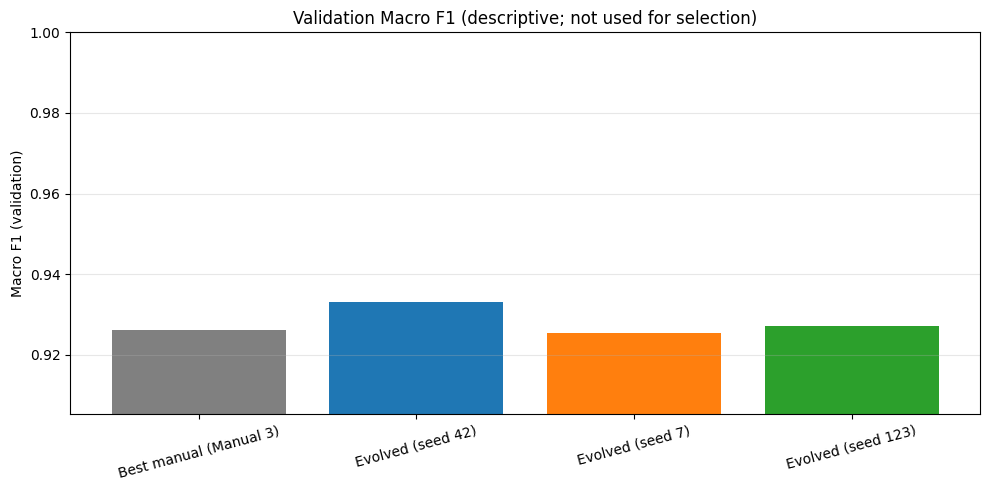

In [16]:
validation_df = splits.val.copy()
val_text_col = "sentence" if "sentence" in validation_df.columns else "text"
assert val_text_col in validation_df.columns and "label" in validation_df.columns

val_examples = validation_df[val_text_col].astype(str).tolist()
val_labels = validation_df["label"].astype(int).tolist()
print("Validation examples:", len(val_examples))

validation_cache = PredictionCache()

val_rows = []
print(f"Evaluating best manual prompt ({best_manual_name}) ...")
val_rows.append(metrics_row(f"Best manual ({best_manual_name})", "Manual",
                            evaluate_on(best_manual_prompt, val_examples, val_labels, validation_cache, "val")))

for s in ALL_SEEDS:
    print(f"Evaluating evolved prompt, seed {s} ...")
    val_rows.append(metrics_row(f"Evolved (seed {s})", "Evolved",
                                evaluate_on(runs[s]["best"]["prompt"], val_examples, val_labels,
                                            validation_cache, "val")))

val_df = pd.DataFrame(val_rows)
display(val_df)
val_df.to_csv(SUMMARY_DIR / "validation_descriptive.csv", index=False)

val_manual_f1 = float(val_df.loc[0, "macro_f1"])
evolved_val = val_df[val_df["type"] == "Evolved"]["macro_f1"].astype(float).to_numpy()
val_stats = {
    "manual_macro_f1": val_manual_f1,
    "evolved_mean": float(np.mean(evolved_val)),
    "evolved_std_sample": float(np.std(evolved_val, ddof=1)),
    "evolved_min": float(np.min(evolved_val)),
    "evolved_max": float(np.max(evolved_val)),
}
print(f"\nValidation: manual {val_manual_f1:.4f} | evolved mean {val_stats['evolved_mean']:.4f} "
      f"(std {val_stats['evolved_std_sample']:.4f}, range {val_stats['evolved_min']:.4f} to {val_stats['evolved_max']:.4f})")

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(val_df["prompt_name"], val_df["macro_f1"],
       color=["gray"] + [colors[s] for s in ALL_SEEDS])
lo = max(0.0, float(val_df["macro_f1"].min()) - 0.02)
ax.set_ylim(lo, 1.0)
ax.set_ylabel("Macro F1 (validation)")
ax.set_title("Validation Macro F1 (descriptive; not used for selection)")
ax.grid(axis="y", alpha=0.3)
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig(SUMMARY_DIR / "validation_descriptive.png", dpi=300)
plt.show()

## G1. Scientific Interpretation (computed from the results)

The text below is generated from the numbers, with fixed caution rules:
- the standard error of Macro F1 on 1,000 examples is about 0.8 points, so smaller gaps cannot be
  separated from sampling noise;
- three runs cannot establish robustness;
- initial-population advantage and post-generation-0 gain are reported separately and are not a causal split.

In [ ]:

spread = stats["range"]

all_beat_manual = bool(
    (summary_df["best_macro_f1_opt"] > best_manual_f1).all()
)
above_manual_gen0 = int(
    (summary_df["gen0_best_f1"] > best_manual_f1).sum()
)

mean_init_adv = float(summary_df["initial_advantage_vs_manual"].mean())
mean_evo_gain = float(summary_df["evolution_gain_after_gen0"].mean())
n_with_evo_gain = int(
    (summary_df["evolution_gain_after_gen0"] > 0).sum()
)

identical_prompts = len(set(prompts_by_seed.values())) < len(prompts_by_seed)

lines = []

lines.append(
    f"Across GA seeds {ALL_SEEDS}, best optimization Macro F1 averaged "
    f"{stats['mean']:.4f} (sample std {stats['std_sample']:.4f}; "
    f"range {stats['min']:.4f} to {stats['max']:.4f}). "
    f"The best manual prompt scored {best_manual_f1:.4f}."
)

if all_beat_manual:
    lines.append(
        "All three runs produced a best evolved prompt that outperformed "
        "the best manual prompt on the optimization set."
    )
else:
    lines.append(
        "Not all runs produced a best evolved prompt above the best manual "
        "prompt on the optimization set."
    )

lines.append(
    f"The spread across seeds was {spread * 100:.2f} percentage points. "
    "This is small in this experiment, but only three runs were conducted, "
    "so the results are insufficient to establish robustness or precisely "
    "characterize seed-to-seed variability."
)

lines.append(
    f"At generation 0, the best score was above the best manual prompt in "
    f"{above_manual_gen0} of 3 runs. The mean initial-population advantage "
    f"was {mean_init_adv * 100:.2f} percentage points. Evolution after "
    f"generation 0 added {mean_evo_gain * 100:.2f} percentage points on "
    f"average and improved the best score in {n_with_evo_gain} of 3 runs. "
    "The observed gain after generation 0 was larger than the initial-"
    "population advantage. This is descriptive, not causal: each initial "
    "population contains the same eight manual prompts plus four "
    "LLM-generated prompts."
)

lines.append(
    "Identical best prompt strings were found across seeds."
    if identical_prompts
    else "The best prompts differ in wording across seeds; see the similarity "
         "matrices and prompt listing above. They share the same basic "
         "instruction to classify sentiment as positive or negative."
)

lines.append(
    f"On validation, the evolved prompts had mean Macro F1 "
    f"{val_stats['evolved_mean']:.4f} "
    f"(range {val_stats['evolved_min']:.4f} to {val_stats['evolved_max']:.4f}) "
    f"versus {val_manual_f1:.4f} for the best manual prompt. Individual "
    "results varied: seeds 42 and 123 exceeded the manual prompt, while "
    "seed 7 scored slightly lower. Validation results were descriptive "
    "and did not select prompts or seeds."
)

lines.append(
    "Limitations: three seeds only; the eight manual prompts were shared "
    "across initial populations; one optimization sample; diversity "
    "measures exact-string uniqueness rather than semantic diversity; "
    "crossover/mutation failure counts were not recorded; some operators "
    "returned a parent after failed retries; the final test set was not used."
)

interpretation = "\n\n".join(lines)
print(interpretation)


Across GA seeds [42, 7, 123], the best optimization Macro F1 was 0.9422 on average (sample std 0.0011, range 0.9415 to 0.9434). The best manual prompt scored 0.9364.

In all three runs the best evolved prompt scored higher than the best manual prompt on the optimization set.

The spread between seeds (0.19 points) is smaller than the roughly 0.8-point standard error of a 1,000-example sample, so the runs cannot be statistically distinguished.

Generation 0 already exceeded the best manual prompt by 0.14 points on average (all runs: False). Evolution after generation 0 added 0.43 points on average, and was positive in 3 of 3 runs. Most of the advantage over the manual prompts may therefore come from the initial population rather than from evolutionary search. This is a comparison, not a causal attribution.

The best prompts differ in wording across seeds; see the similarity matrices and prompt listing above.

Validation Macro F1 of the three evolved prompts: mean 0.9285 (range 0.9254 to

## G2. Save Final Summary and Create the ZIP

Saves `multi_seed_summary.json` and an archive with only the new material
(`experiment_seed_7`, `experiment_seed_123`, `multi_seed_summary`). The original `experiment_01`
results are not included and not changed.

In [18]:
final = {
    "experiment": "Multi-seed Genetic Algorithm prompt optimization",
    "dataset": "SST-2",
    "model": llm.model_id,
    "model_revision": model_config.revision,
    "data_seed": DATA_SEED,
    "data_hash": DATA_HASH,
    "ga_seeds": ALL_SEEDS,
    "seed_42_loaded_from": str(seed42_dir),
    "hyperparameters": HYPERPARAMETERS,
    "best_manual_prompt": {
        "name": best_manual_name,
        "prompt": best_manual_prompt,
        "macro_f1_opt": best_manual_f1,
        "accuracy_opt": best_manual_acc,
    },
    "per_seed": summary_df.to_dict(orient="records"),
    "best_macro_f1_opt_statistics": stats,
    "validation_descriptive": {
        "rows": val_df.to_dict(orient="records"),
        "statistics": val_stats,
        "note": "Descriptive only. Validation was not used to select prompts or seeds.",
    },
    "interpretation": interpretation,
    "test_set_used": False,
    "created_at": datetime.now().isoformat(),
}

summary_path = SUMMARY_DIR / "multi_seed_summary.json"
with open(summary_path, "w", encoding="utf-8") as f:
    json.dump(final, f, indent=4, ensure_ascii=False, default=str)
print("Saved:", summary_path)

ZIP_FILE = Path("/kaggle/working/multi_seed_experiment.zip")
with zipfile.ZipFile(ZIP_FILE, "w", zipfile.ZIP_DEFLATED) as z:
    for folder in ["experiment_seed_7", "experiment_seed_123", "multi_seed_summary"]:
        base = RUNS_ROOT / folder
        for p in sorted(base.rglob("*")):
            if p.is_file():
                z.write(p, arcname=str(Path(folder) / p.relative_to(base)))

with zipfile.ZipFile(ZIP_FILE) as z:
    print("\nFiles in archive:")
    for n in z.namelist():
        print("-", n)

display(FileLink(str(ZIP_FILE)))

Saved: /kaggle/working/outputs/genetic_algorithm/multi_seed_summary/multi_seed_summary.json

Files in archive:
- experiment_seed_7/best_individual.json
- experiment_seed_7/best_prompt.txt
- experiment_seed_7/history.csv
- experiment_seed_7/history.json
- experiment_seed_7/run_meta.json
- experiment_seed_123/best_individual.json
- experiment_seed_123/best_prompt.txt
- experiment_seed_123/history.csv
- experiment_seed_123/history.json
- experiment_seed_123/run_meta.json
- multi_seed_summary/computational_cost.csv
- multi_seed_summary/computational_cost.png
- multi_seed_summary/diversity_all_seeds.png
- multi_seed_summary/fitness_evolution_all_seeds.png
- multi_seed_summary/multi_seed_comparison.csv
- multi_seed_summary/multi_seed_summary.json
- multi_seed_summary/validation_descriptive.csv
- multi_seed_summary/validation_descriptive.png


/kaggle/working/multi_seed_experiment.zip